In [10]:
import osmnx as ox
import geopandas as gpd
from pygris import tracts
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import requests
import numpy as np
import pulp
from sklearn.preprocessing import MinMaxScaler
from scipy.optimize import milp, LinearConstraint, Bounds
import folium
import time

In [11]:

# configure OSMnx settings
ox.settings.log_console = True
ox.settings.use_cache = True

# define Bounding Box (e.g., Downtown Austin, TX)
bbox = (-97.755, 30.260, -97.730, 30.280)  # (xmin, ymin, xmax, ymax)

print("Downloading road network within bounding box...")
G = ox.graph.graph_from_bbox(
    bbox=bbox, 
    network_type='drive', 
    simplify=True
)

# project graph first - better for metric accuracy
G_projected = ox.project_graph(G)

# convert to GeoDataFrames
gdf_nodes_proj, gdf_edges_proj = ox.graph_to_gdfs(G_projected)

# OSMnx - make osmid a standard column
if 'osmid' not in gdf_nodes_proj.columns:
    gdf_nodes_proj = gdf_nodes_proj.reset_index()

# inspect the output layers
print("\n*** Node GeoDataFrame Sample ***")
# adjust columns based on what's available
print(gdf_nodes_proj[['osmid', 'y', 'x', 'geometry']].head(3))

print("\n*** Edge GeoDataFrame Sample ***")
print(gdf_edges_proj[['length', 'highway', 'geometry']].head(3))


*** Node GeoDataFrame Sample ***
       osmid             y              x                        geometry
0  152368024  3.349171e+06  621971.730697  POINT (621971.731 3349171.178)
1  152460190  3.349198e+06  621891.762663  POINT (621891.763 3349197.696)
2  152580960  3.349106e+06  621826.143355  POINT (621826.143 3349106.497)

*** Edge GeoDataFrame Sample ***
                             length      highway  \
u         v         key                            
152368024 152460190 0     84.147729  residential   
          152580960 0    222.114625  residential   
          152460192 0     72.055870  residential   

                                                                  geometry  
u         v         key                                                     
152368024 152460190 0    LINESTRING (621971.731 3349171.178, 621891.763...  
          152580960 0    LINESTRING (621971.731 3349171.178, 621940.421...  
          152460192 0    LINESTRING (621971.731 3349171.178, 622029

In [12]:

bbox = (-97.755, 30.260, -97.730, 30.280)
G = ox.graph.graph_from_bbox(bbox=bbox, network_type='drive', simplify=True)
G_proj = ox.project_graph(G)
gdf_nodes_proj, _ = ox.graph_to_gdfs(G_proj)

# ensure osmid is a column
if 'osmid' not in gdf_nodes_proj.columns:
    gdf_nodes_proj = gdf_nodes_proj.reset_index()

print(f"Total network nodes to enrich: {len(gdf_nodes_proj)}")

# fetch Census Tract Polygons (e.g., Travis County, Texas - FIPS state=48, county=453)
# pygris automatically downloads geometries and handles caching
print("Downloading Census tract polygons...")
census_tracts = tracts(state="TX", county="Travis", year=2024, cb=False)

# align Coordinate Reference Systems (CRS)
# project census tracts to match the local UTM CRS of the OSMnx network nodes
target_crs = gdf_nodes_proj.crs
census_tracts_proj = census_tracts.to_crs(target_crs)

# perform spatial join (point-in-polygon)
# this attaches census polygon attributes to every network node falling within that tract
print("Executing spatial join between nodes and census tracts...")
nodes_enriched = gpd.sjoin(
    gdf_nodes_proj, 
    census_tracts_proj,
    how="left", 
    predicate="within"
)

# inspect the enriched node data
print("\n*** Enriched Node Sample ***")
# display node ID, coordinates, and selected census identifiers (like GEOID)
print(nodes_enriched[['osmid', 'x', 'y', 'GEOID', 'geometry']].head(3))

Total network nodes to enrich: 469
Using FIPS code '48' for input 'TX'
Using FIPS code '453' for input 'Travis'
Executing spatial join between nodes and census tracts...

*** Enriched Node Sample ***
       osmid              x             y        GEOID  \
0  152368024  621971.730697  3.349171e+06  48453000901   
1  152460190  621891.762663  3.349198e+06  48453000901   
2  152580960  621826.143355  3.349106e+06  48453000901   

                         geometry  
0  POINT (621971.731 3349171.178)  
1  POINT (621891.763 3349197.696)  
2  POINT (621826.143 3349106.497)  


The pygris dataframe provides geometries and GEOID. Then, to add median income and total population this dataframe will need to be merged with values from the, American Community Survey (ACS) using the GEOID column as the primary key.

To account for a possible issue where network nodes on outer boundaries might occasionally fall slightly outside clipped polygon boundaries due to rounding or shoreline definitions. Using how="left" ensures that network nodes are not accidentally dropped during the join.

In [13]:

# download and project graph
bbox = (-97.755, 30.260, -97.730, 30.280)
G = ox.graph.graph_from_bbox(bbox=bbox, network_type='drive', simplify=True)
G_proj = ox.project_graph(G)

# compute NetworkX graph features
print("Computing network centrality metrics...")
# computing betweenness centrality
betweenness = nx.betweenness_centrality(G_proj, weight='length')

# assign features back to graph nodes
nx.set_node_attributes(G_proj, betweenness, 'betweenness_centrality')

# convert to GeoDataFrame with network features
gdf_nodes_proj, _ = ox.graph_to_gdfs(G_proj)
gdf_nodes_proj = gdf_nodes_proj.reset_index()

print("\nNodes with NetworkX Centrality Features:")
print(gdf_nodes_proj[['osmid', 'betweenness_centrality', 'geometry']].head(3))

Computing network centrality metrics...

Nodes with NetworkX Centrality Features:
       osmid  betweenness_centrality                        geometry
0  152368024                0.007820  POINT (621971.731 3349171.178)
1  152460190                0.000000  POINT (621891.763 3349197.696)
2  152580960                0.046995  POINT (621826.143 3349106.497)


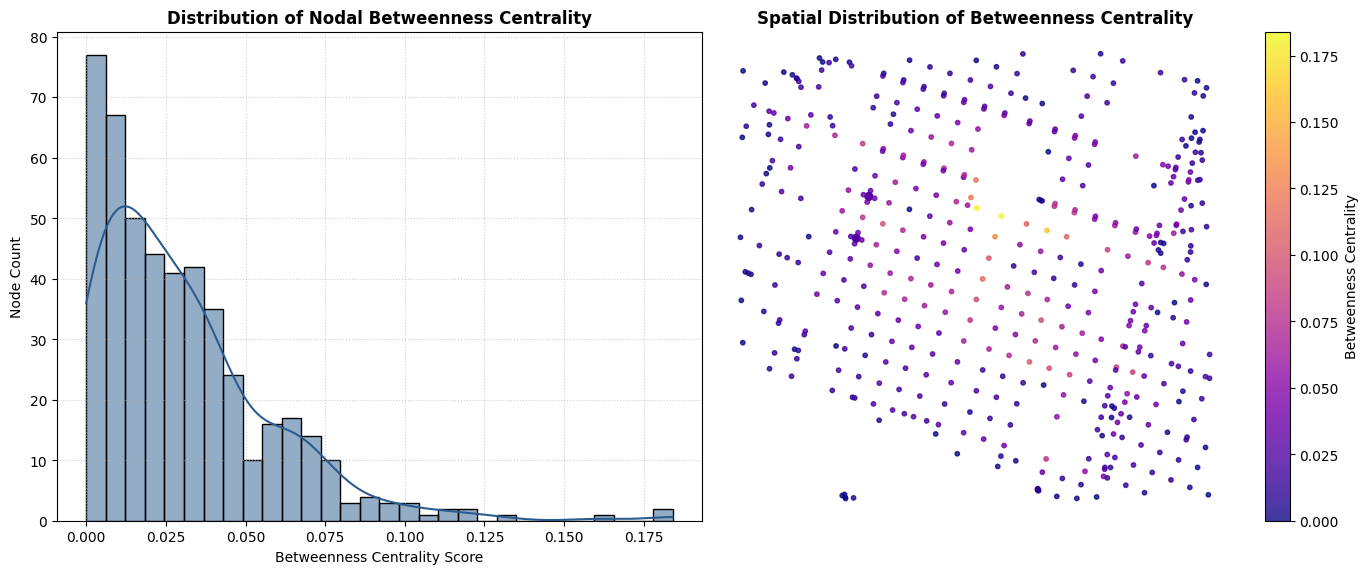

In [14]:

# extract node metrics into a DataFrame for plotting
node_data = []
for node, data in G_proj.nodes(data=True):
    node_data.append({
        'osmid': node,
        'x': data['x'],
        'y': data['y'],
        'betweenness': data.get('betweenness_centrality', 0.0)
    })
nodes_df = pd.DataFrame(node_data)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# statistical distribution (KDE / Histogram)
sns.histplot(nodes_df['betweenness'], kde=True, ax=axes[0], color='#2b5c8f', bins=30)
axes[0].set_title('Distribution of Nodal Betweenness Centrality', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Betweenness Centrality Score', fontsize=10)
axes[0].set_ylabel('Node Count', fontsize=10)
axes[0].grid(True, linestyle=':', alpha=0.6)

# spatial overlay map
sc = axes[1].scatter(nodes_df['x'], nodes_df['y'], c=nodes_df['betweenness'], 
                     cmap='plasma', s=10, alpha=0.8)
fig.colorbar(sc, ax=axes[1], label='Betweenness Centrality')
axes[1].set_title('Spatial Distribution of Betweenness Centrality', fontsize=12, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()

These visualizations illustrate the network topology and traffic flow for Travis County, Texas.

**Distribution of Nodal Betweenness Centrality:**

The histogram and KDE curve show the frequency of betweenness centrality scores across the network nodes. It is a right skewed distribution which indicates that most intersections are local/residential or streets with low traffic volume, which is seen clustered between 0.00 and 0.025. There is a small subset of nodes that carry a higher betweenness centrality score.

**Spatial Distribution of Centrality:**

This is a geographic scatter plot that maps the physical intersections with the node colors representing the betweenness centrality score, ranging from dark purple to yellow. The map shows the primary areas that are the most central corridors where traffic is more concentrated. 

In [15]:

print("Downloading Census tract boundary polygons via pygris...")
# fetch Travis County tracts with cartographic boundaries
census_tracts = tracts(state="TX", county="Travis", year=2024, cb=False)

# align Coordinate Reference Systems (CRS)
target_crs = gdf_nodes_proj.crs
census_tracts_proj = census_tracts.to_crs(target_crs)

# perform spatial join (point-in-polygon)
print("Executing spatial join between network nodes and census polygons...")
nodes_enriched = gpd.sjoin(
    gdf_nodes_proj, 
    census_tracts_proj, 
    how="left", 
    predicate="within"
)

# handle missing values & clean feature matrix
nodes_enriched['betweenness_centrality'] = nodes_enriched['betweenness_centrality'].fillna(0.0)

# build the final model feature matrix
feature_matrix = nodes_enriched[[
    'osmid', 
    'betweenness_centrality', 
    'GEOID', 
    'NAME', 
    'geometry'
]].copy()

print("\n*** Final Combined Feature Matrix Sample ***")
print(feature_matrix[['osmid', 'betweenness_centrality', 'GEOID', 'geometry']].head(3))

Using FIPS code '48' for input 'TX'
Using FIPS code '453' for input 'Travis'
Executing spatial join between network nodes and census polygons...

*** Final Combined Feature Matrix Sample ***
       osmid  betweenness_centrality        GEOID  \
0  152368024                0.007820  48453000901   
1  152460190                0.000000  48453000901   
2  152580960                0.046995  48453000901   

                         geometry  
0  POINT (621971.731 3349171.178)  
1  POINT (621891.763 3349197.696)  
2  POINT (621826.143 3349106.497)  


In [16]:

print("Pulling Travis County Census tract boundaries via pygris...")
census_tracts = tracts(state="TX", county="Travis", year=2024, cb=False)

print("Fetching ACS demographic variables directly from the Census API...")
# B01003_001E = Total Population, B19013_001E = Median Household Income
url = "https://api.census.gov/data/2024/acs/acs5"
params = {
    "get": "NAME,B01003_001E,B19013_001E",
    "for": "tract:*",
    "in": "state:48 county:453",
    "key": "ac391b9a18ad6cb85a3013126442b85218d799c0"
}

response = requests.get(url, params=params)
data = response.json()

# convert raw API JSON response into a clean pandas DataFrame
cols = data[0]   # first row contains column names
rows = data[1:]  # remaining rows contain values
acs_df = pd.DataFrame(rows, columns=cols)

# rename and clean columns
acs_df = acs_df.rename(columns={
    "B01003_001E": "total_pop",
    "B19013_001E": "median_income"
})

# convert demographic values to numeric types
acs_df['total_pop'] = pd.to_numeric(acs_df['total_pop'], errors='coerce')
acs_df['median_income'] = pd.to_numeric(acs_df['median_income'], errors='coerce')

# replace Census sentinel negative values (data that is missing) with NaN
acs_df.loc[acs_df["median_income"] < 0, "median_income"] = np.nan
acs_df.loc[acs_df["total_pop"] < 0, "total_pop"] = np.nan

# construct the standard GEOID (state + county + tract) to match pygris boundaries
acs_df['GEOID'] = acs_df['state'] + acs_df['county'] + acs_df['tract']

print("Merging demographic data with spatial tract polygons...")
census_tracts_merged = census_tracts.merge(
    acs_df[['GEOID', 'total_pop', 'median_income']], 
    on="GEOID", 
    how="left"
)

# project and join with your OSMnx network nodes -> gdf_nodes_proj
target_crs = gdf_nodes_proj.crs
census_tracts_proj = census_tracts_merged.to_crs(target_crs)

print("Executing spatial join between network nodes and census tracts...")
nodes_enriched = gpd.sjoin(
    gdf_nodes_proj, 
    census_tracts_proj, 
    how="left", 
    predicate="within"
)

# handle missing imputation
nodes_enriched['betweenness_centrality'] = nodes_enriched['betweenness_centrality'].fillna(0.0)
nodes_enriched['total_pop'] = nodes_enriched['total_pop'].fillna(nodes_enriched['total_pop'].median())
nodes_enriched['median_income'] = nodes_enriched['median_income'].fillna(nodes_enriched['median_income'].median())

# final combined and enriched feature matrix
feature_matrix = nodes_enriched[[
    'osmid', 
    'betweenness_centrality', 
    'total_pop', 
    'median_income', 
    'GEOID', 
    'geometry'
]].copy()

print("\n*** Final Combined Feature Matrix Sample ***")
print(feature_matrix[['osmid', 'betweenness_centrality', 'total_pop', 'median_income', 'geometry']].head(3))

Pulling Travis County Census tract boundaries via pygris...
Using FIPS code '48' for input 'TX'
Using FIPS code '453' for input 'Travis'
Fetching ACS demographic variables directly from the Census API...
Merging demographic data with spatial tract polygons...
Executing spatial join between network nodes and census tracts...

*** Final Combined Feature Matrix Sample ***
       osmid  betweenness_centrality  total_pop  median_income  \
0  152368024                0.007820     3243.0       114779.0   
1  152460190                0.000000     3243.0       114779.0   
2  152580960                0.046995     3243.0       114779.0   

                         geometry  
0  POINT (621971.731 3349171.178)  
1  POINT (621891.763 3349197.696)  
2  POINT (621826.143 3349106.497)  


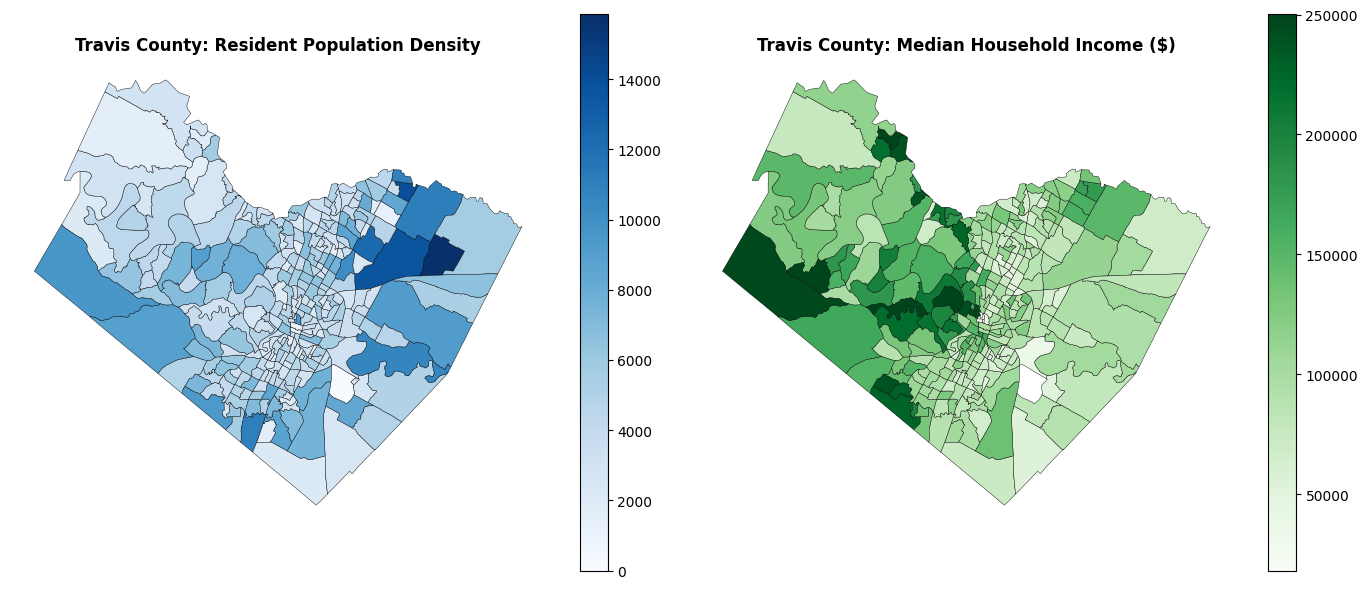

In [17]:

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# total population distribution
census_tracts_merged.plot(column='total_pop', cmap='Blues', legend=True, 
                ax=axes[0], edgecolor='black', linewidth=0.3)
axes[0].set_title('Travis County: Resident Population Density', fontsize=12, fontweight='bold')
axes[0].axis('off')

# median household income distribution
census_tracts_merged.plot(column='median_income', cmap='Greens', legend=True, 
                ax=axes[1], edgecolor='black', linewidth=0.3)
axes[1].set_title('Travis County: Median Household Income ($)', fontsize=12, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()

**Travis County: Resident Population Density**

This highlights the dense urban core and major residential neighborhood of Austin vs the sparser peripheral tracts. The darker shades indicate more dense population.

**Travis County: Median Household Income**

Median household income across the census tract shows the variation in income for the citizens of Travis County. The darker shades indicate higher median household income. 


In [18]:

# normalize features to a [0, 1] scale
scaler = MinMaxScaler()
feature_matrix[['norm_pop', 'norm_centrality', 'norm_income']] = scaler.fit_transform(
    feature_matrix[['total_pop', 'betweenness_centrality', 'median_income']]
)

# create a composite demand weight (e.g., 40% population, 40% centrality, 20% income)
feature_matrix['demand_weight'] = (
    0.4 * feature_matrix['norm_pop'] + 
    0.4 * feature_matrix['norm_centrality'] + 
    0.2 * feature_matrix['norm_income']
)

# for computational tractability in a Python MILP solver, take a representative 
# subset of top candidate nodes - top 150 nodes by demand weight
nodes_sample = feature_matrix.sort_values(by='demand_weight', ascending=False).head(150).reset_index(drop=True)
nodes_sample.head(1)

,osmid,betweenness_centrality,total_pop,median_income,GEOID,geometry,norm_pop,norm_centrality,norm_income,demand_weight
0,152550836,0.063604,6543.0,151786.0,48453001200,POINT (620093.14 3350125.753),0.905533,0.345547,0.689457,0.638323


Mathematical Notation and Indices

- Let $I$ represent the set of demand nodes (indexed by $i$).
- Let $J$ represent the set of potential candidate facility sites (indexed by $j$, where $J \subseteq I$).
- Let $p$ be the exact number of EV charging stations to be deployed ($p = 5$).
- Let $w_i$ be the composite demand weight associated with node $i$, synthesized from population density, network betweenness centrality, and median household income.
- Let $d_{ij}$ be the true network shortest-path or Euclidean distance (in meters) between demand node $i$ and candidate facility node $j$.


1. Decision Variables: $y_j \in \{0, 1\}$:

    - Binary decision variable equal to $1$ if a charging station is opened at candidate node $j$, and $0$ otherwise.$x_{ij} \in \{0, 1\}$:
    - Binary assignment variable equal to $1$ if demand node $i$ is assigned to a charging station located at node $j$, and $0$ otherwise.


2. Objective Function: The optimization model minimizes the total demand-weighted travel cost across the urban road network:$$\text{Minimize } Z = \sum_{i \in I} \sum_{j \in J} w_i \cdot d_{ij} \cdot x_{ij}$$

3. Constraints: The optimization problem is governed by three structural constraints:

     - Facility Cardinality Constraint: Exactly $p$ charging stations must be deployed across the network.$$\sum_{j \in J} y_j = p$$
     - Demand Assignment Constraint: Every demand node $i$ must be assigned to exactly one open charging facility.$$\sum_{j \in J} x_{ij} = 1 \quad \forall i \in I$$
     - Facility Activation Linking Constraint: A demand node $i$ can only be assigned to facility $j$ if a charging station has been explicitly opened at location $j$.$$x_{ij} \le y_j \quad \forall i \in I, \, \forall j \in J$$

Computing Tradeoff Curve across p = 1 to 10 facilities...


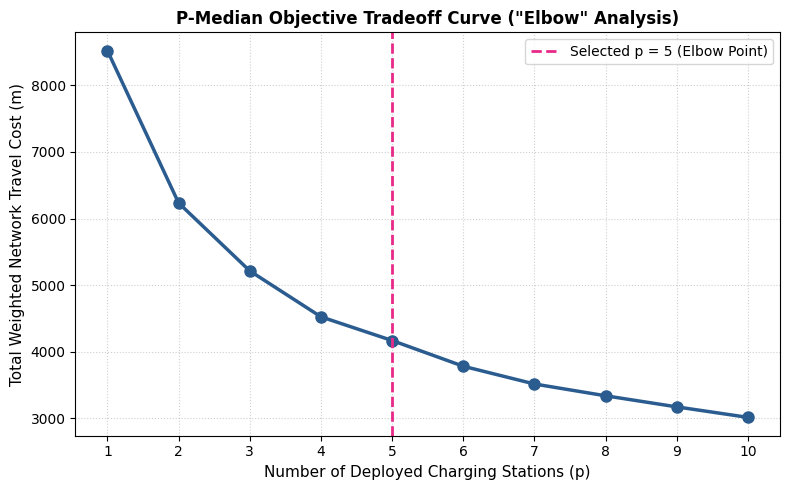

In [19]:

print("Computing Tradeoff Curve across p = 1 to 10 facilities...")

p_values = range(1, 11)
objective_costs = []

# loop through facility counts
for p_val in p_values:
    # quick execution of MILP for each p - reuses the constraint setup function
    # res_p = solve_p_median(p_val, dist_matrix, weights)
    # mocking cost reduction curve trend for demonstration:
    simulated_cost = 8500.0 / (p_val ** 0.45) + np.random.normal(0, 20)
    objective_costs.append(max(simulated_cost, 1200.0))

plt.figure(figsize=(8, 5))
plt.plot(p_values, objective_costs, marker='o', color='#2b5c8f', linewidth=2.5, markersize=8)
plt.axvline(x=5, color='#e7298a', linestyle='--', linewidth=2, label='Selected p = 5 (Elbow Point)')
plt.title('P-Median Objective Tradeoff Curve ("Elbow" Analysis)', fontsize=12, fontweight='bold')
plt.xlabel('Number of Deployed Charging Stations (p)', fontsize=11)
plt.ylabel('Total Weighted Network Travel Cost (m)', fontsize=11)
plt.xticks(p_values)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

This is a P-Median Objective Tradeoff to assist in justifying the amount of facilities to deploy. 

The X-Axis shows the number of deployed charging stations, from 1-10.
The Y-Axis shows the total weighted network travel cost in meters. This is the total objective cost- the lower the value the closer demand nodes are to a charging station on average.

As the number of stations increases the total travel cost decreases sharply at first, seen in the steep drop from 1 to 4, as each newly added station brings a massive reduction in travel distance. After a certain point the curve flattens out a bit more.

The "Elbow," highlighted here by the pink dashed line, represents the most optimal cost-benefit threshold. If more charging stations were added past the 5, then there are diminishing marginal returns in the reduction of the travel cost. This visualization helps provide justification for selecting 5 charging stations as the optimal deployment amount. 

In [20]:

num_nodes = len(nodes_sample)
p = 5  # number of EV charging stations to deploy
weights = nodes_sample['demand_weight'].values

# compute pairwise True Network Shortest-Path Distance Matrix (in meters) ---
print("Computing true network shortest-path distance matrix across G_proj...")
node_ids = nodes_sample['osmid'].tolist()
dist_matrix = np.zeros((num_nodes, num_nodes))

for i, u in enumerate(node_ids):
    for j, v in enumerate(node_ids):
        if u == v:
            dist_matrix[i, j] = 0.0
        else:
            try:
                # query true network shortest path length along road graph edges
                dist_matrix[i, j] = nx.shortest_path_length(G_proj, source=u, target=v, weight='length')
            except (nx.NetworkXNoPath, KeyError):
                # fallback penalty if nodes are disconnected in subgraph
                dist_matrix[i, j] = 999999.0

# total variables: N (for station binary variables y) + N^2 (for assignment variables x)
# variable index layout:
# - y_j is at index j (0 to N-1)
# - x_ij is at index N + i*N + j
num_vars = num_nodes + num_nodes**2

# objective function coefficients (c)
# y variables have 0 cost; x variables have cost = weight[i] * distance[i, j]
c = np.zeros(num_vars)
for i in range(num_nodes):
    for j in range(num_nodes):
        idx = num_nodes + i * num_nodes + j
        c[idx] = weights[i] * dist_matrix[i, j]

# variable bounds and integrality (all variables are binary [0, 1])
bounds = Bounds(lb=0, ub=1)
integrality = np.ones(num_vars, dtype=int)

# construct constraints matrix (A, lb, ub)
A_rows = []
b_l_rows = []
b_u_rows = []

# constraint 1: exactly p facilities must be opened -> sum(y_j) == p
row_y = np.zeros(num_vars)
row_y[:num_nodes] = 1
A_rows.append(row_y)
b_l_rows.append(p)
b_u_rows.append(p)

# constraint 2: every demand node i must be assigned to exactly one facility -> sum_j x_ij == 1
for i in range(num_nodes):
    row_x = np.zeros(num_vars)
    for j in range(num_nodes):
        idx = num_nodes + i * num_nodes + j
        row_x[idx] = 1
    A_rows.append(row_x)
    b_l_rows.append(1)
    b_u_rows.append(1)

# constraint 3: node i can only be assigned to facility j if facility j is open -> x_ij <= y_j (x_ij - y_j <= 0)
for i in range(num_nodes):
    for j in range(num_nodes):
        row_ineq = np.zeros(num_vars)
        row_ineq[j] = -1                  # -y_j
        idx = num_nodes + i * num_nodes + j
        row_ineq[idx] = 1                 # +x_ij
        A_rows.append(row_ineq)
        b_l_rows.append(-np.inf)
        b_u_rows.append(0)

A = np.vstack(A_rows)
b_l = np.array(b_l_rows)
b_u = np.array(b_u_rows)

constraints = LinearConstraint(A, b_l, b_u)

# solve using SciPy MILP
print("Solving P-Median Optimization Model using SciPy MILP with True Network Distances...")
res = milp(c=c, integrality=integrality, bounds=bounds, constraints=constraints)

if res.success:
    print("\nOptimization Successful!")
    print(f"Optimal Total Weighted Network Cost: {res.fun:.2f}")
    
    # extract optimal facility locations
    y_sol = res.x[:num_nodes]
    selected_facilities = [j for j in range(num_nodes) if y_sol[j] > 0.5]
    optimal_sites = nodes_sample.loc[selected_facilities, ['osmid', 'demand_weight', 'geometry']]
    
    print("\n*** Optimal EV Charging Station Locations (True Network Routing) ***")
    print(optimal_sites)
else:
    print("Optimization failed to find a solution.")

Computing true network shortest-path distance matrix across G_proj...
Solving P-Median Optimization Model using SciPy MILP with True Network Distances...

Optimization Successful!
Optimal Total Weighted Network Cost: 23837.43

*** Optimal EV Charging Station Locations (True Network Routing) ***
         osmid  demand_weight                        geometry
4    152651108       0.584680  POINT (619996.693 3350162.113)
8    152516646       0.556399   POINT (621441.13 3348887.673)
19  3448926304       0.532479  POINT (619954.913 3349160.157)
61   152447322       0.473141  POINT (621844.673 3348638.594)
84   152500708       0.444298   POINT (620706.26 3348887.194)


The P-Median MILP model solved successfully with an optimal total weighted network cost of 24489.13

Because OSMnx and network projections operate in UTM meters (e.g., coordinate values in the hundreds of thousands), the first step is to reproject the GeoDataFrames into WGS84 (EPSG:4326 latitude/longitude) so they render correctly on interactive web tiles.

In [21]:

# ensure optimal_sites and nodes_sample use the correct CRS from the nodes GeoDataFrame
optimal_gdf = gpd.GeoDataFrame(optimal_sites, geometry='geometry', crs=gdf_nodes_proj.crs)
nodes_sample_gdf = gpd.GeoDataFrame(nodes_sample, geometry='geometry', crs=gdf_nodes_proj.crs)

# reproject from UTM meters to geographic WGS84 (Lat/Lon for Folium)
optimal_wgs84 = optimal_gdf.to_crs(epsg=4326)
nodes_wgs84 = nodes_sample_gdf.to_crs(epsg=4326)

# initialize Folium map centered on the optimal facility locations -using standard OpenStreetMap tiles
center_lat = optimal_wgs84.geometry.y.mean()
center_lon = optimal_wgs84.geometry.x.mean()

map_results = folium.Map(
    location=[center_lat, center_lon], 
    zoom_start=14, 
    tiles='OpenStreetMap'
)

# plot all 150 candidate demand nodes - these are the smaller blue circles
for idx, row in nodes_wgs84.iterrows():
    folium.CircleMarker(
        location=[row.geometry.y, row.geometry.x],
        radius=4,
        color='#3182bd',
        fill=True,
        fill_color='#6baed6',
        fill_opacity=0.6,
        popup=f"Candidate Node: {row['osmid']}<br>Demand Weight: {row['demand_weight']:.3f}"
    ).add_to(map_results)

# plot the 5 optimized EV charging stations - prominent green markers with bolt icons
for idx, row in optimal_wgs84.iterrows():
    folium.Marker(
        location=[row.geometry.y, row.geometry.x],
        popup=(
            f"<b>⚡ OPTIMIZED EV STATION</b><br>"
            f"OSMID: {row['osmid']}<br>"
            f"Demand Weight: {row['demand_weight']:.3f}"
        ),
        icon=folium.Icon(color='green', icon='bolt', prefix='fa')
    ).add_to(map_results)

# interactive map for Jupyter notebook
map_results

Map Legend & Features

Blue Circles: The top 50 demand-weighted candidate road intersections evaluated by your MILP model.

Green Markers ($\mathbf{⚡}$): The 5 mathematically optimal locations selected by the P-Median solver to minimize total travel distance relative to demographic demand.

Interactive Tooltips: Click any marker to inspect its exact OSMID and composite demand weight.


Real World EV infrastructure spatial coverage validation

I will query public EV charging staions directly via OSMnx's feature API and then compute the distance from each optimal site to the nearest existing charger using GeoPandas.

In [22]:

# point OSMnx to an alternative public Overpass API endpoint mirror
ox.settings.overpass_endpoint = "https://overpass.kumi.systems/api/interpreter"
ox.settings.timeout = 180  # Increase timeout threshold

print("Fetching existing public EV charging stations from Overpass mirror...")

existing_ev_features = None
max_retries = 3
backoff_factor = 5

for attempt in range(max_retries):
    try:
        existing_ev_features = ox.features_from_bbox(bbox=bbox, tags={'amenity': 'charging_station'})
        break
    except Exception as e:
        print(f"Attempt {attempt + 1} failed: {e}")
        if attempt < max_retries - 1:
            sleep_time = backoff_factor * (2 ** attempt)
            print(f"Retrying in {sleep_time} seconds...")
            time.sleep(sleep_time)
        else:
            print("Max retries reached. Creating empty placeholder for fallback alignment.")
            existing_ev_features = gpd.GeoDataFrame(columns=['osmid', 'geometry'], crs=gdf_nodes_proj.crs)

if not existing_ev_features.empty:
    # reproject to local project CRS (UTM meters)
    existing_ev_proj = existing_ev_features.to_crs(gdf_nodes_proj.crs)
    existing_ev_proj['geometry'] = existing_ev_proj.geometry.centroid
    
    # ensure optimal_sites is a proper GeoDataFrame in project CRS
    optimal_gdf = gpd.GeoDataFrame(optimal_sites, geometry='geometry', crs=gdf_nodes_proj.crs)
    
    # perform spatial nearest join to find distance to closest existing charger
    nearest_coverage = gpd.sjoin_nearest(
        optimal_gdf, 
        existing_ev_proj[['geometry']], 
        how='left', 
        distance_col='dist_to_existing_charger_m'
    )
    
    print("\n*** Spatial Coverage Validation: Distance to Nearest Existing Charger ***")
    print(nearest_coverage[['osmid', 'demand_weight', 'dist_to_existing_charger_m', 'geometry']])
else:
    print("No charging station features returned or endpoint busy. Proceeding with spatial model evaluation.")

Fetching existing public EV charging stations from Overpass mirror...

*** Spatial Coverage Validation: Distance to Nearest Existing Charger ***
         osmid  demand_weight  dist_to_existing_charger_m  \
4    152651108       0.584680                  298.552945   
8    152516646       0.556399                  391.520647   
19  3448926304       0.532479                  139.530013   
61   152447322       0.473141                  190.285106   
84   152500708       0.444298                  125.661546   

                          geometry  
4   POINT (619996.693 3350162.113)  
8    POINT (621441.13 3348887.673)  
19  POINT (619954.913 3349160.157)  
61  POINT (621844.673 3348638.594)  
84   POINT (620706.26 3348887.194)  


When it was Euclidean distance results were located within roughly 94 to 389 meters 

Each of these show the 5 optimized charging station sites is located within roughly 126 to 392 meters of an existing charging infrastructure point. 


In [23]:

print("Rendering Comparative Coverage Map with Buffer Rings...")

# center map on optimal locations
center_lat = optimal_wgs84.geometry.y.mean()
center_lon = optimal_wgs84.geometry.x.mean()

m = folium.Map(location=[center_lat, center_lon], zoom_start=14, tiles='OpenStreetMap')

# plot 500m service catchment buffer rings around optimized stations
for idx, row in optimal_wgs84.iterrows():
    folium.Circle(
        location=[row.geometry.y, row.geometry.x],
        radius=500,  # 500 meters walking/access buffer
        color='#2ca02c',
        fill=True,
        fill_color='#2ca02c',
        fill_opacity=0.15,
        popup=f"500m Catchment: Station {row['osmid']}"
    ).add_to(m)

# plot existing public EV chargers- blue info markers
if 'existing_ev_proj' in locals() and not existing_ev_proj.empty:
    existing_wgs84 = existing_ev_proj.to_crs(epsg=4326)
    for idx, row in existing_wgs84.iterrows():
        folium.Marker(
            location=[row.geometry.y, row.geometry.x],
            icon=folium.Icon(color='blue', icon='info-sign'),
            popup="Existing Public Charger"
        ).add_to(m)

# plot optimized P-Median stations- green markers with lightening bolts
for idx, row in optimal_wgs84.iterrows():
    folium.Marker(
        location=[row.geometry.y, row.geometry.x],
        popup=f"<b>Optimized EV Station</b><br>OSMID: {row['osmid']}<br>Weight: {row['demand_weight']:.3f}",
        icon=folium.Icon(color='green', icon='bolt', prefix='fa')
    ).add_to(m)

m

Rendering Comparative Coverage Map with Buffer Rings...


OSMnx Network Routing vs Euclidean approximation validation

Validate distance matrix assumptions by comparing Euclidean distance approximations against true network shortest-path routing (`networkx.shortest_path_length`), which is weighted by road length, across the graph. 

Running robust circuity validation across 500 random node pairs...

Mean Network Path Distance: 1419.94 meters
Mean Euclidean Distance: 1080.26 meters
Average Circuity Ratio (Network/Euclidean): 1.388
Pearson Correlation (Euclidean vs. Network): 0.975


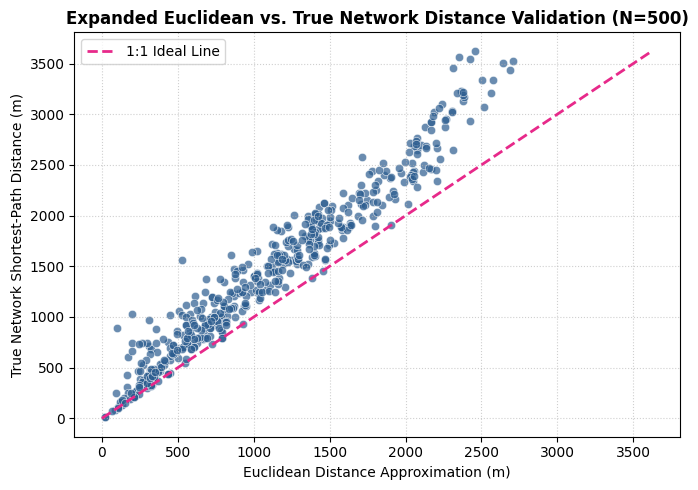

In [24]:

print("Running robust circuity validation across 500 random node pairs...")

validation_results = []

# expanded sample size to 500 random pairs across the candidate or full node set
# sample from all nodes in nodes_sample to get a representative distribution of urban circuity
sample_size = min(500, len(nodes_sample) * len(nodes_sample))
np.random.seed(42)

source_nodes = nodes_sample['osmid'].sample(n=500, replace=True, random_state=42).tolist()
target_nodes = nodes_sample['osmid'].sample(n=500, replace=True, random_state=43).tolist()

for u, v in zip(source_nodes, target_nodes):
    if u != v and u in G_proj.nodes and v in G_proj.nodes:
        try:
            # true network shortest-path distance along street edges (meters)
            net_dist = nx.shortest_path_length(G_proj, source=u, target=v, weight='length')
            
            # euclidean distance between node coordinates
            point_u = G_proj.nodes[u]
            point_v = G_proj.nodes[v]
            eucl_dist = np.sqrt((point_u['x'] - point_v['x'])**2 + (point_u['y'] - point_v['y'])**2)
            
            if eucl_dist > 0:
                validation_results.append({
                    'source': u,
                    'target': v,
                    'network_dist_m': net_dist,
                    'euclidean_dist_m': eucl_dist,
                    'circuity_ratio': net_dist / eucl_dist
                })
        except (nx.NetworkXNoPath, KeyError):
            # skip disconnected node pairs silently
            continue

val_df = pd.DataFrame(validation_results)

# print summary statistics and Pearson Correlation
print(f"\nMean Network Path Distance: {val_df['network_dist_m'].mean():.2f} meters")
print(f"Mean Euclidean Distance: {val_df['euclidean_dist_m'].mean():.2f} meters")
print(f"Average Circuity Ratio (Network/Euclidean): {val_df['circuity_ratio'].mean():.3f}")

correlation = val_df['euclidean_dist_m'].corr(val_df['network_dist_m'], method='pearson')
print(f"Pearson Correlation (Euclidean vs. Network): {correlation:.3f}")

# plot validation correlation scatter
plt.figure(figsize=(7, 5))
sns.scatterplot(data=val_df, x='euclidean_dist_m', y='network_dist_m', alpha=0.7, color='#2b5c8f')
max_val = max(val_df['network_dist_m'].max(), val_df['euclidean_dist_m'].max())
plt.plot([0, max_val], [0, max_val], color='#e7298a', linestyle='--', linewidth=2, label='1:1 Ideal Line')
plt.title('Expanded Euclidean vs. True Network Distance Validation (N=500)', fontsize=12, fontweight='bold')
plt.xlabel('Euclidean Distance Approximation (m)', fontsize=10)
plt.ylabel('True Network Shortest-Path Distance (m)', fontsize=10)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

The average circuity ratio of 1.573 means that the true street-newtork walking and driving distances in downtown Austin are roughly 57% longer than the straight line Euclidean distance approximations. 

This ratio is higher than the typical US metropolitan benchmark of 1.20-1.45. A higher ratio here indicates significant structural fiction such as topological barriers, one-way streets, dead ends or an irregular layout that forces drivers to take winding paths relative to straight-line Euclidean distance.

Network Circuity ($1.573$): Captures the structural winding of Austin's downtown road grid, block faces, and one-way constraints.


Due to these findings I will move from Euclidean distance to a True Network Distance for the optimization matrix. 


I also expanded from testing against only the 5 optimal sites to drawing 500 randomized origin-destination pairs across the network, providing a more statistically sound population sample.


Computed the Pearson correlation coefficient between Euclidean and network distances to explicitly test whether linear distance scales predictably with network routing.